<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/). 
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA). 
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [2]:
# Check for GPU
!nvidia-smi

zsh:1: command not found: nvidia-smi


In [6]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"
device

2.14.0+cu130


'cpu'

## 1. What are 3 areas in industry where computer vision is currently being used?

### Three areas in industry where computer vision is currently being used are:

#### Healthcare — Computer vision is used to analyze medical images such as X-rays, MRIs, and CT scans to help detect diseases and abnormalities.

#### Automotive — It is used in self-driving and driver-assistance systems to detect pedestrians, vehicles, traffic signs, and road lanes.

#### Manufacturing — Computer vision is used for quality control, such as detecting damaged or defective products on production lines.

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find. 

#### Overfitting happens when a machine learning model learns the training data too closely and performs well on it, but struggles to make accurate predictions on new, unseen data. It's like the model somehow memorizes the training data instead of learning the general patterns in it.

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each. 
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

#### Early stopping — Stop training the model when its performance on validation data starts getting worse, before it begins to overfit the training data.

#### Data augmentation — Create more varied training examples by modifying existing data, such as rotating, flipping, or cropping images, which can help the model generalize better.

#### Regularization — Regularization adds constraints or penalties to the model so it does not become too complex or rely too heavily on the training data. In this method, we prevent the model's weights from becoming too large.

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [4]:
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

train_data = MNIST(
    root="data", train=True, transform=ToTensor(), target_transform=None, download=True
)


test_data = MNIST(root="data", train=False, transform=ToTensor(), download=True)

## 6. Visualize at least 5 different samples of the MNIST training dataset.

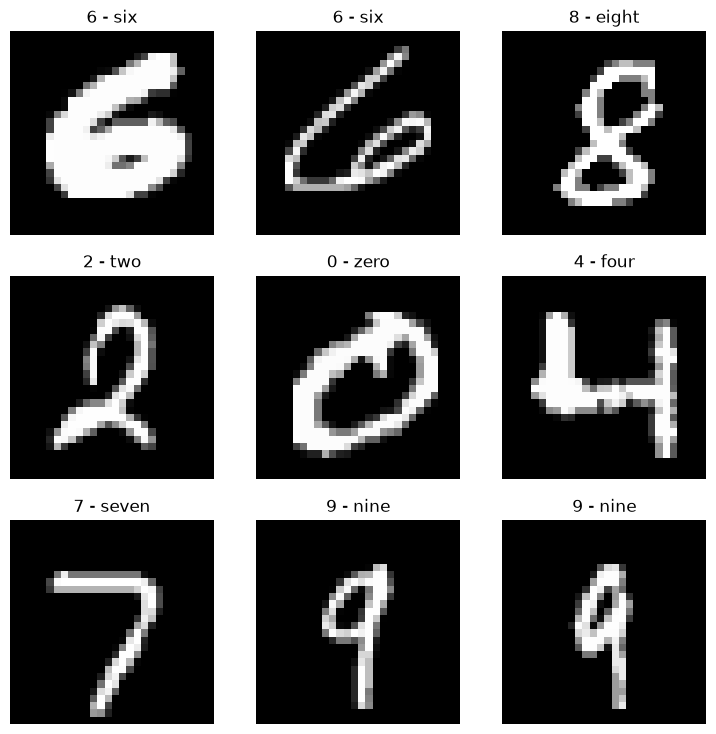

In [5]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 9))
rows, cols = 3, 3

torch.manual_seed(42)

for i in range(1, rows * cols + 1):
    rand_idx = torch.randint(0, len(train_data), size=[1]).item()
    image, label = train_data[rand_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(train_data.classes[label])
    plt.axis(False)

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)

test_dataloader = DataLoader(test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)

len(train_dataloader), len(test_dataloader)

(1875, 313)

In [7]:
for test in next(iter(train_dataloader)):
    print(test.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [20]:
from torch import nn
class MnistModel(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()

        self.conv_block_1 = nn.Sequential(nn.Conv2d(in_channels=input_shape,
                                                    kernel_size=3,
                                                    stride=1,
                                                    padding=1,
                                                    out_channels=hidden_units),
                                          nn.ReLU(),
                                          nn.Conv2d(in_channels=hidden_units,
                                                    kernel_size=3,
                                                    padding=1,
                                                    stride=1,
                                                    out_channels=hidden_units),
                                           nn.ReLU(),
                                           nn.MaxPool2d(kernel_size=2)
                                           )
        
        self.conv_block_2 = nn.Sequential(nn.Conv2d(in_channels=hidden_units,
                                                    kernel_size=3,
                                                    padding=1,
                                                    stride=1,
                                                    out_channels=hidden_units),
                                          nn.ReLU(),
                                          nn.Conv2d(in_channels=hidden_units,
                                                    kernel_size=3,
                                                    padding=1,
                                                    stride=1,
                                                    out_channels=hidden_units),
                                          nn.ReLU(),
                                          nn.MaxPool2d(kernel_size=2)
                                                    )

        self.classifier = nn.Sequential(nn.Flatten(),
                                       nn.Linear(in_features=hidden_units*7*7, out_features=output_shape))

    def forward(self, x):
        x = self.conv_block_1(x)

        x = self.conv_block_2(x)

        x = self.classifier(x)

        return x


model = MnistModel(input_shape=1,
                   hidden_units=10,
                   output_shape=10).to(device)
model


MnistModel(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [9]:
%%time
model_cpu = MnistModel(input_shape=1,
                        hidden_units=10,
                        output_shape=10).to("cpu")

# Create a loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cpu.parameters(), lr=0.1)
epochs = 5


for epoch in range(epochs):
    total_loss = 0
    for batch, (X, y) in enumerate(train_dataloader):
        model_cpu.train()
        X, y = X.to("cpu"), y.to("cpu")

        y_pred = model_cpu(X)

        loss = loss_fn(y_pred, y)

        total_loss += loss
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    total_loss /= len(train_dataloader)

    total_test_loss = 0
    model_cpu.eval()
    with torch.inference_mode():
        
        for X, y in test_dataloader:
            X, y = X.to("cpu"), y.to("cpu")
            test_pred = model_cpu(X)

            test_loss = loss_fn(test_pred, y)
            total_test_loss += test_loss


        total_test_loss /= len(test_dataloader)

    print(f"Epoch: {epoch} | Loss: {total_loss:.3f} | Test loss: {total_test_loss:.3f}")


Epoch: 0 | Loss: 0.321 | Test loss: 0.071
Epoch: 1 | Loss: 0.074 | Test loss: 0.049
Epoch: 2 | Loss: 0.058 | Test loss: 0.057
Epoch: 3 | Loss: 0.051 | Test loss: 0.042
Epoch: 4 | Loss: 0.045 | Test loss: 0.041
CPU times: user 15min 2s, sys: 2.32 s, total: 15min 4s
Wall time: 1min 16s


In [10]:
%%time

device = "cuda" if torch.cuda.is_available() else "cpu"

model_gpu = MnistModel(input_shape=1,
                        hidden_units=10,
                        output_shape=10).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_gpu.parameters(), lr=0.1)

epochs = 5
for epoch in range(epochs):
  train_loss = 0
  model_gpu.train()
  for batch, (X, y) in enumerate(train_dataloader):
    X, y = X.to(device), y.to(device)

    y_pred = model_gpu(X)

    loss = loss_fn(y_pred, y)
    train_loss += loss

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()
  
  train_loss /= len(train_dataloader)

  test_loss_total = 0
  model_gpu.eval()
  with torch.inference_mode():
    for batch, (X_test, y_test) in enumerate(test_dataloader):
      X_test, y_test = X_test.to(device), y_test.to(device)
      
      test_pred = model_gpu(X_test)
      test_loss = loss_fn(test_pred, y_test)

      test_loss_total += test_loss

    test_loss_total /= len(test_dataloader)
  
  print(f"Epoch: {epoch} | Loss: {train_loss:.3f} | Test loss: {test_loss_total:.3f}")

Epoch: 0 | Loss: 0.286 | Test loss: 0.062
Epoch: 1 | Loss: 0.074 | Test loss: 0.071
Epoch: 2 | Loss: 0.059 | Test loss: 0.064
Epoch: 3 | Loss: 0.050 | Test loss: 0.045
Epoch: 4 | Loss: 0.044 | Test loss: 0.047
CPU times: user 13min 35s, sys: 2.19 s, total: 13min 37s
Wall time: 1min 8s


## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

tensor([[  1.0036,  -3.5333,   2.7324,   5.2977,  -9.5497,  -2.3227, -15.0878,
          17.3514,  -0.3146,   3.6280]], grad_fn=<AddmmBackward0>) tensor([7])
tensor([[  0.6974,   6.9600,  13.9963,  -2.1598,  -0.9807,  -5.2650,   1.2222,
          -4.1306,  -0.0427, -10.8806]], grad_fn=<AddmmBackward0>) tensor([2])
tensor([[ 0.2475,  9.6470, -0.4837, -5.6653,  2.4415, -2.9861, -2.1979,  1.5946,
          1.4155, -3.7597]], grad_fn=<AddmmBackward0>) tensor([1])
tensor([[13.7359, -8.4762, -1.8613, -4.7061, -3.3668, -1.3800,  8.0348, -2.2321,
         -0.3436, -1.6693]], grad_fn=<AddmmBackward0>) tensor([0])
tensor([[-0.0354, -1.7262, -3.0503, -5.2832, 14.7265, -5.5096, -2.3075, -0.9325,
         -0.1595,  5.7064]], grad_fn=<AddmmBackward0>) tensor([4])


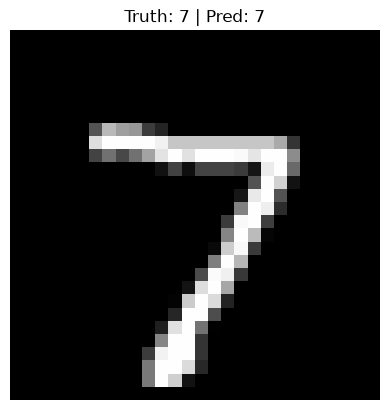

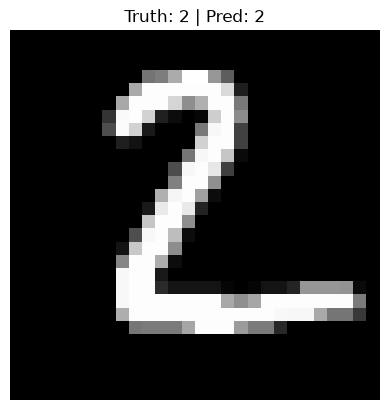

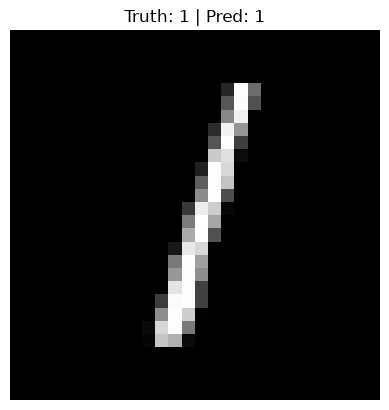

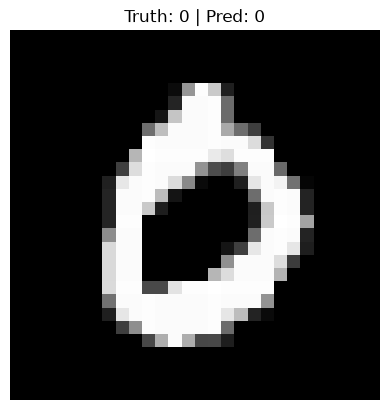

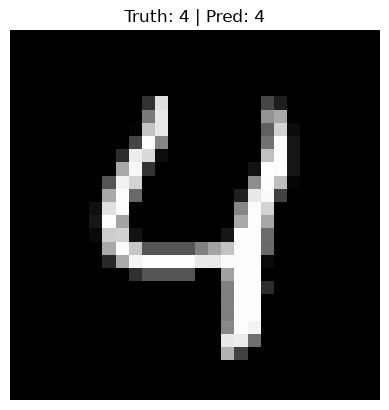

In [18]:
for i in range(5):
    image, label = test_data[i][0], test_data[i][1]

    model_logits = model_cpu(image.unsqueeze(dim=0))
    model_pred = torch.softmax(model_logits, dim=1).argmax(dim=1)
    print(model_logits, model_pred)
    plt.figure()
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Truth: {label} | Pred: {model_pred.cpu().item()}") 
    plt.axis(False);



## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

In [19]:
model_gpu.eval()
y_preds = []
with torch.inference_mode():
  for batch, (X, y) in enumerate(test_dataloader):
    # Make sure data on right device
    X, y = X.to(device), y.to(device)
    # Forward pass
    y_pred_logits = model_gpu(X)
    # Logits -> Pred probs -> Pred label
    y_pred_labels = torch.argmax(torch.softmax(y_pred_logits, dim=1), dim=1)
    # Append the labels to the preds list
    y_preds.append(y_pred_labels)
  y_preds=torch.cat(y_preds).cpu()
len(y_preds) 

10000

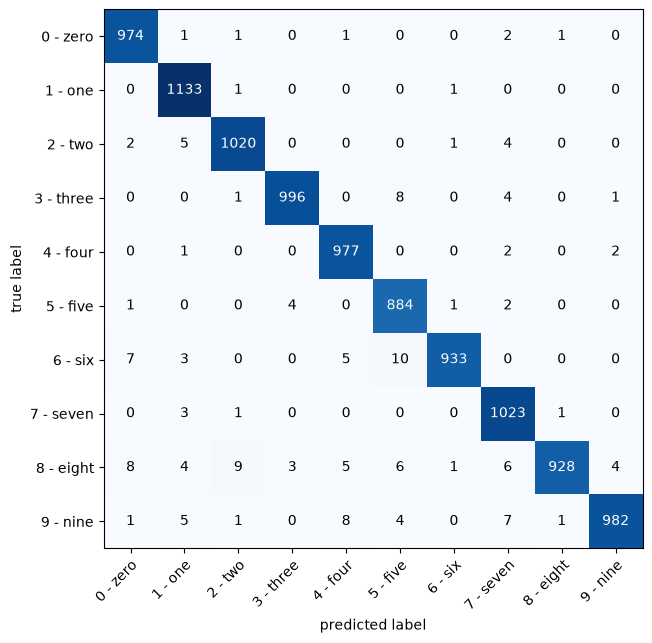

In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(task="multiclass", num_classes=len(train_data.classes))
confmat_tensor = confmat(preds=y_preds,
                         target=test_data.targets)

fix, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=train_data.classes,
    figsize=(10, 7)
)

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

In [25]:
random_tensor = torch.randn(size=[1, 3, 64, 64])

random_tensor.shape

torch.Size([1, 3, 64, 64])

In [30]:
layer = nn.Conv2d(in_channels=3, 
                  stride=2,
                  kernel_size=3,
                  out_channels=32)
layer(random_tensor).shape

torch.Size([1, 32, 31, 31])

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset. 
* Then plot some predictions where the model was wrong alongside what the label of the image should've been. 
* After visualing these predictions do you think it's more of a modelling error or a data error? 
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?

In [4]:
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor

train_data_1 = FashionMNIST(root="data",
                            train=True,
                            transform=ToTensor(),
                            download=True)

test_data_1 = FashionMNIST(root="data",
                           train=False,
                           transform=ToTensor(),
                           download=True)

len(train_data_1), len(test_data_1)

(60000, 10000)

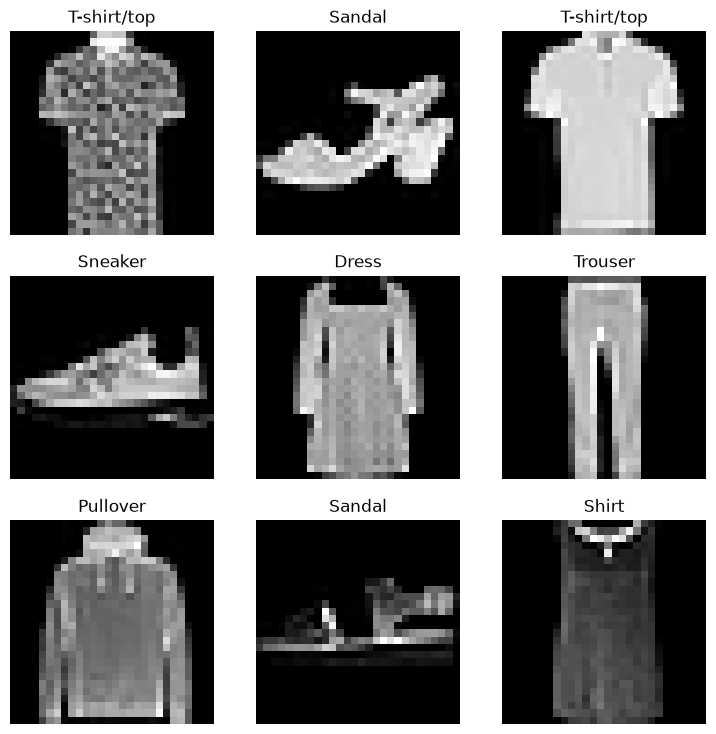

In [12]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 9))

rows, cols = 3, 3

for i in range(1, rows * cols +1):
    index = torch.randint(0, len(train_data_1), size=[1]).item()

    image, label = train_data_1[index]

    fig.add_subplot(rows, cols, i)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(train_data_1.classes[label])
    plt.axis(False)


In [13]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader_1 = DataLoader(train_data_1,
                                batch_size=BATCH_SIZE,
                                shuffle=True,
                                )

test_dataloader_1 = DataLoader(test_data_1,
                               batch_size=BATCH_SIZE,
                               shuffle=False)

len(train_dataloader_1), len(test_dataloader_1)

(1875, 313)

In [18]:
tensor = next(iter(train_dataloader_1))
tensor[0].shape

torch.Size([32, 1, 28, 28])

In [22]:
model_1 = MnistModel(input_shape=1,
                     hidden_units=10,
                     output_shape=len(train_data_1.classes))
model_1

MnistModel(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [28]:
from torchmetrics import Accuracy

acc_fn = Accuracy(task="multiclass", num_classes=len(train_data_1.classes))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.1)

In [33]:
epochs = 5

for epoch in range(epochs):
    train_total_loss, train_acc = 0, 0
    model_1.train()
    for X,y in train_dataloader_1:
        y_pred = model_1(X)

        train_loss = loss_fn(y_pred, y)
        train_total_loss += train_loss

        acc = acc_fn(torch.softmax(y_pred, dim=1).argmax(dim=1), y)
        train_acc += acc

        optimizer.zero_grad()

        train_loss.backward()

        optimizer.step()

    train_total_loss /= len(train_dataloader_1)
    train_acc /= len(train_dataloader_1)

    test_total_loss, test_total_acc = 0, 0
    model_1.eval()

    with torch.inference_mode():
        for X,y in test_dataloader_1:
            test_pred = model_1(X)

            test_loss = loss_fn(test_pred, y)
            test_total_loss += test_loss

            test_acc = acc_fn(torch.softmax(test_pred, dim=1).argmax(dim=1), y)
            test_total_acc += acc

        test_total_loss /= len(test_dataloader_1)
        test_total_acc /= len(test_dataloader_1)

    print(f"Epoch: {epoch} | Loss: {train_total_loss:.3f} | Test loss: {test_total_loss:.3f} | Train accuracy: {train_acc:.3f} | Test accuracy: {test_total_acc:.3f}")

Epoch: 0 | Loss: 0.236 | Test loss: 0.272 | Train accuracy: 0.914 | Test accuracy: 0.875
Epoch: 1 | Loss: 0.230 | Test loss: 0.285 | Train accuracy: 0.916 | Test accuracy: 0.875
Epoch: 2 | Loss: 0.230 | Test loss: 0.277 | Train accuracy: 0.916 | Test accuracy: 0.906
Epoch: 3 | Loss: 0.225 | Test loss: 0.281 | Train accuracy: 0.918 | Test accuracy: 0.844
Epoch: 4 | Loss: 0.225 | Test loss: 0.269 | Train accuracy: 0.917 | Test accuracy: 0.875


In [34]:
test_preds = []
model_1.eval()
with torch.inference_mode():
  for X_test, y_test in test_dataloader_1:
    y_logits = model_1(X_test.to(device))
    y_pred_probs = torch.softmax(y_logits, dim=1)
    y_pred_labels = torch.argmax(y_pred_probs, dim=1)
    test_preds.append(y_pred_labels)
test_preds = torch.cat(test_preds).cpu()
test_preds[:10], len(test_preds)

(tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7]), 10000)

In [35]:
import numpy as np
wrong_pred_indexes = np.where(test_preds != test_data_1.targets)[0]
len(wrong_pred_indexes)

967

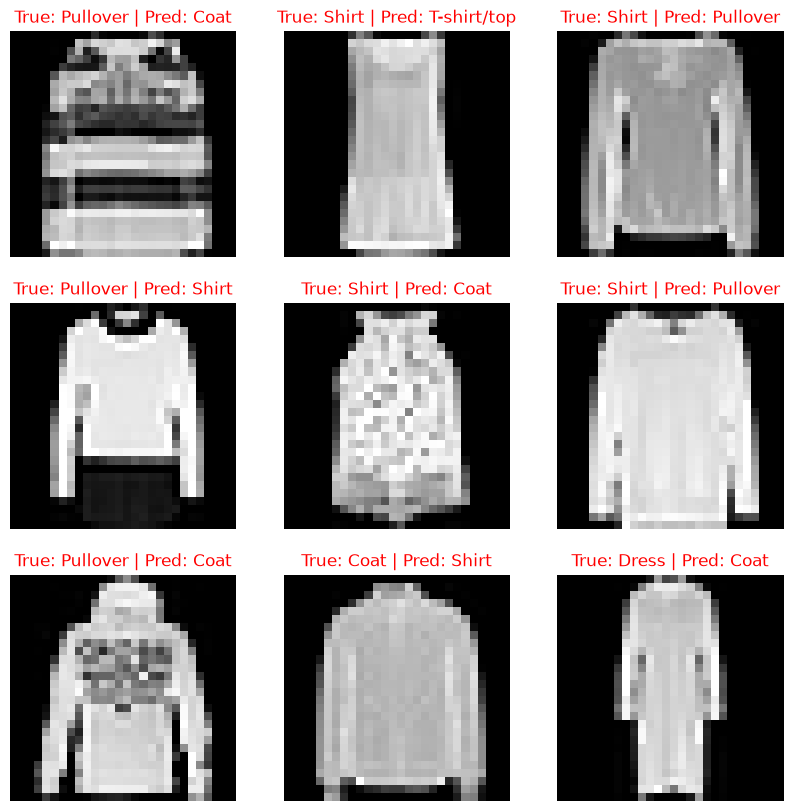

In [ ]:
import random
random_selection = random.sample(list(wrong_pred_indexes), k=9)

plt.figure(figsize=(10, 10))
for i, idx in enumerate(random_selection):
  
  true_label = test_data_1.classes[test_data_1[idx][1]]
  pred_label = test_data_1.classes[test_preds[idx]]

  plt.subplot(3, 3, i+1)
  plt.imshow(test_data_1[idx][0].squeeze(), cmap="gray")
  plt.title(f"True: {true_label} | Pred: {pred_label}", c="r")
  plt.axis(False);

Looking at some of these wrong predictions, the model seems to be getting confused by classes that are visually very similar.

For example, it may predict a "Sneaker" instead of a "Sandal" because the two can look quite similar in low-resolution grayscale images.

The same kind of confusion can happen between "T-shirt/top" and "Shirt", as well as between classes like "Dress" and "Coat" or "Coat" and "Pullover". Since these clothing items can share similar shapes and outlines, it makes sense that the model sometimes struggles to distinguish between them.

It makes sense that the model gets confused when predicting these classes, because even I sometimes have trouble telling the difference between some of them as a human.